## Implement a learning rate scheduler in Neural Networks by manually adjusting learning rates during training based on performance trends, avoiding built-in schedulers and ensuring stable weight updates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('heart.csv')                          
X_all, y_all = df.drop(columns='target').values.astype(float), df['target'].values.astype(float)

def split(seed):
    idx = np.random.default_rng(seed).permutation(len(X_all)); a, b = int(0.6 * len(idx)), int(0.8 * len(idx))
    tr, va, te = idx[:a], idx[a:b], idx[b:]
    mu, sd = X_all[tr].mean(0), X_all[tr].std(0)
    f = lambda i: ((X_all[i] - mu) / sd, y_all[i])
    return f(tr), f(va), f(te)
print('Rows:', len(X_all))

Rows: 303


In [2]:
sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def init(rng, n_in=13, n_h=16):
    return dict(W1=rng.normal(0, np.sqrt(2 / n_in), (n_in, n_h)), b1=np.zeros(n_h), W2=rng.normal(0, np.sqrt(2 / n_h), (n_h, 1)), b2=np.zeros(1))

def forward(P, X):
    h = np.maximum(0, X @ P['W1'] + P['b1'])
    return h, sigmoid(h @ P['W2'] + P['b2'])[:, 0]

def loss_acc(P, X, y):
    p = np.clip(forward(P, X)[1], 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)), np.mean((p > 0.5) == y)

def grads(P, X, y):
    h, p = forward(P, X); dz2 = ((p - y) / len(y))[:, None]
    dh = (dz2 @ P['W2'].T) * (h > 0)
    return dict(W1=X.T @ dh, b1=dh.sum(0), W2=h.T @ dz2, b2=dz2.sum(0))

In [3]:
class Constant:
    def __init__(s, lr): s.lr = lr
    def step(s, ep, val): return s.lr

class StepDecay:                                       
    def __init__(s, lr, drop=0.5, every=25): s.lr0, s.drop, s.every, s.lr = lr, drop, every, lr
    def step(s, ep, val): s.lr = s.lr0 * s.drop ** ((ep + 1) // s.every); return s.lr

class ExpDecay:                                     
    def __init__(s, lr, gamma=0.97): s.lr0, s.gamma, s.lr = lr, gamma, lr
    def step(s, ep, val): s.lr = s.lr0 * s.gamma ** (ep + 1); return s.lr

class Plateau:                                       
    def __init__(s, lr, factor=0.5, patience=6, min_lr=1e-3): s.lr, s.factor, s.patience, s.min_lr, s.best, s.wait = lr, factor, patience, min_lr, np.inf, 0
    def step(s, ep, val):
        if val < s.best - 1e-3: s.best, s.wait = val, 0
        else: s.wait += 1
        if s.wait > s.patience: s.lr, s.wait = max(s.lr * s.factor, s.min_lr), 0     
        return s.lr

In [4]:
def train(sched, seed, epochs=100, bs=32, mom=0.9, wd=0.01, clip=None, guard=False):
    (Xt, yt), (Xv, yv), (Xs, ys) = split(seed); rng = np.random.default_rng(seed)
    P = init(rng); V = {k: np.zeros_like(v) for k, v in P.items()}
    H = dict(lr=[], train=[], val=[], upd=[], fires=0); best_val, best_P = np.inf, {k: v.copy() for k, v in P.items()}
    for ep in range(epochs):
        order = rng.permutation(len(yt)); max_upd = 0
        for i in range(0, len(yt), bs):
            b = order[i:i + bs]; G = grads(P, Xt[b], yt[b])
            if clip:                                                       
                norm = np.sqrt(sum((g ** 2).sum() for g in G.values()))
                if norm > clip: G = {k: g * clip / norm for k, g in G.items()}
            for k in P:
                V[k] = mom * V[k] - sched.lr * (G[k] + (wd * P[k] if k[0] == 'W' else 0)); P[k] = P[k] + V[k]   
            max_upd = max(max_upd, np.sqrt(sum((v ** 2).sum() for v in V.values())))
        val, _ = loss_acc(P, Xv, yv); H['lr'].append(sched.lr); H['train'].append(loss_acc(P, Xt, yt)[0]); H['val'].append(val); H['upd'].append(max_upd)
        if guard and (not np.isfinite(val) or val > 1.5 * best_val):        # divergence: best weights wapas, lr aadha
            P = {k: v.copy() for k, v in best_P.items()}; V = {k: np.zeros_like(v) for k, v in P.items()}; sched.lr *= 0.5; H['fires'] += 1
        elif val < best_val: best_val, best_P = val, {k: v.copy() for k, v in P.items()}
        sched.step(ep, val)
    H['test'] = loss_acc(P, Xs, ys); return H

In [5]:
configs = {
    'Constant (0.3)':       (lambda: Constant(0.3), None, False),
    'Constant (0.01)':      (lambda: Constant(0.01), None, False),
    'Step decay':           (lambda: StepDecay(0.3), None, False),
    'Exp decay':            (lambda: ExpDecay(0.3), None, False),
    'Plateau':              (lambda: Plateau(0.3), None, False),
    'Plateau + clip + guard': (lambda: Plateau(0.3), 5.0, True),
}
runs0 = {n: train(mk(), 0, clip=c, guard=g) for n, (mk, c, g) in configs.items()}      
print({n: round(H['val'][-1], 3) for n, H in runs0.items()})

{'Constant (0.3)': np.float64(0.488), 'Constant (0.01)': np.float64(0.49), 'Step decay': np.float64(0.451), 'Exp decay': np.float64(0.46), 'Plateau': np.float64(0.446), 'Plateau + clip + guard': np.float64(0.446)}


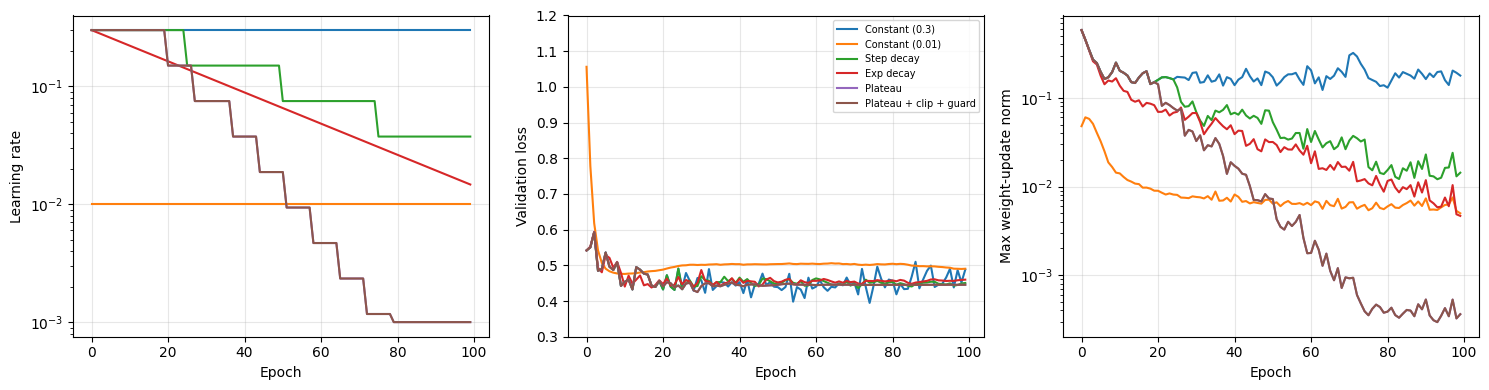

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for n, H in runs0.items():
    axes[0].plot(H['lr'], label=n); axes[1].plot(H['val'], label=n); axes[2].plot(H['upd'], label=n)
axes[0].set_ylabel('Learning rate'); axes[0].set_yscale('log'); axes[1].set_ylabel('Validation loss'); axes[1].set_ylim(0.3, 1.2)
axes[2].set_ylabel('Max weight-update norm'); axes[2].set_yscale('log')
for ax in axes: ax.set_xlabel('Epoch'); ax.grid(alpha=0.3)
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [7]:
rows = []
for n, (mk, c, g) in configs.items():
    R = [train(mk(), s, clip=c, guard=g) for s in range(10)]
    val = np.array([H['val'] for H in R]); upd = np.array([H['upd'] for H in R])
    rise = lambda v: np.sum(v[1:] > 1.1 * v[:-1])                              
    reach = lambda v: np.argmax(v < 0.5) if np.any(v < 0.5) else len(v)                 
    rows.append((n, f"{np.mean([H['test'][0] for H in R]):.3f} +- {np.std([H['test'][0] for H in R]):.3f}", f"{np.mean([H['test'][1] for H in R]):.3f}", f"{np.mean([reach(v) for v in val]):.0f}",
                 f"{val.min(1).mean():.3f}", f"{val[:, -1].mean():.3f}", f"{val[:, -20:].std(1).mean():.4f}", f"{np.mean([rise(v) for v in val]):.1f}", f"{upd.max(1).mean():.2f}"))
pd.DataFrame(rows, columns=['Scheduler', 'Test loss (final epoch)', 'Test acc', 'Epochs to val<0.5', 'Best val loss', 'Final val loss', 'Val jitter (last 20)', 'Val spikes', 'Max update norm'])

,Scheduler,Test loss (final epoch),Test acc,Epochs to val<0.5,Best val loss,Final val loss,Val jitter (last 20),Val spikes,Max update norm
0,Constant (0.3),0.449 +- 0.090,0.823,11,0.371,0.463,0.0296,17.7,0.53
1,Constant (0.01),0.419 +- 0.064,0.828,13,0.401,0.436,0.0032,0.0,0.05
2,Step decay,0.456 +- 0.094,0.821,11,0.385,0.465,0.0044,6.0,0.53
3,Exp decay,0.456 +- 0.098,0.820,11,0.392,0.458,0.0027,3.9,0.53
4,Plateau,0.445 +- 0.097,0.811,11,0.389,0.458,0.0002,2.7,0.53
5,Plateau + clip + guard,0.438 +- 0.090,0.811,11,0.389,0.448,0.0002,2.7,0.53


In [8]:
stress = {'Constant (1.0)': (lambda: Constant(1.0), None, False), 'Plateau (1.0)': (lambda: Plateau(1.0), None, False),
          'Plateau + clip + guard (1.0)': (lambda: Plateau(1.0), 5.0, True)}
rows = []
for n, (mk, c, g) in stress.items():
    R = [train(mk(), s, clip=c, guard=g) for s in range(10)]; val = np.array([H['val'] for H in R])
    rows.append((n, f"{np.nanmean([H['test'][0] for H in R]):.3f}", f"{np.mean([H['test'][1] for H in R]):.3f}", f"{val.min(1).mean():.3f}",
                 f"{np.mean([H['fires'] for H in R]):.1f}", f"{np.mean([np.sum(v[1:] > 1.1 * v[:-1]) for v in val]):.1f}"))
pd.DataFrame(rows, columns=['Scheduler', 'Test loss', 'Test acc', 'Best val loss', 'Guard fires', 'Val spikes'])

,Scheduler,Test loss,Test acc,Best val loss,Guard fires,Val spikes
0,Constant (1.0),0.649,0.652,0.345,0.0,27.4
1,Plateau (1.0),0.474,0.798,0.373,0.0,7.2
2,Plateau + clip + guard (1.0),0.467,0.808,0.370,1.2,4.5
